In [37]:
import os
import json
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

In [ ]:
DATA_PATH = "../VQA Dataset/"
questions_file = DATA_PATH + "questions/v2_OpenEnded_mscoco_val2014_questions.json"
annotations_file = DATA_PATH + "annotations/v2_mscoco_val2014_annotations.json"
images_path = DATA_PATH + "images/val2014/"
image_files = os.listdir(images_path)
df = pd.read_csv("VQA_Dataset.csv")

# 1- Pytorch Environment

In [72]:
import torch
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

PyTorch version: 2.6.0
CUDA available: False
Device name: CPU


# 2- Image Preprocessing

### Image Resolution inspectation

In [74]:
from PIL import Image
for img_name in image_files[:5]:  
    img = Image.open(os.path.join(images_path, img_name))
    print(img_name, img.size)

COCO_val2014_000000265550.jpg (640, 429)
COCO_val2014_000000106073.jpg (424, 640)
COCO_val2014_000000109340.jpg (640, 426)
COCO_val2014_000000150235.jpg (640, 480)
COCO_val2014_000000099747.jpg (640, 480)


We definitly need an image resolution transformation

### 2.1- Image Transformation

In [42]:
from torchvision import transforms

image_transform = transforms.Compose([
    transforms.Resize((224, 224)),          # resize images
    transforms.ToTensor(),                  # convert to tensor [0,1]
    transforms.Normalize(                   # ImageNet normalization
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

### 2.2- Image Dataset Class

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt
from torch.utils.data import Dataset


class ImageDataset(Dataset):
    def __init__(self, images_path, image_ids, transform=None):
        """
        PyTorch Dataset for loading images from COCO VQA dataset.

        Parameters
        ----------
        images_path : str
            Path to the directory containing images.
        image_ids : list
            List of image IDs (integers).
        transform : callable, optional
            Transformations to apply to each image (e.g., resize, normalization).
        """
        self.images_path = images_path
        self.image_ids = image_ids
        self.transform = transform

    def __len__(self):
        """
        Return the total number of images.
        """
        return len(self.image_ids)

    def __getitem__(self, index):
        """
        Load a single image and return it with its image_id.

        Parameters
        ----------
        index : int
            Index of the sample.

        Returns
        -------
        img : Tensor or PIL Image
            Transformed image.
        image_id : int
            Corresponding image ID.
        """
        image_id = self.image_ids[index]
        image_name = f"COCO_val2014_{image_id:012d}.jpg"
        image_path = os.path.join(self.images_path, image_name)

        try:
            img = Image.open(image_path).convert("RGB")
        except FileNotFoundError:
            # Handle missing image gracefully
            raise FileNotFoundError(f"Image not found: {image_path}")

        if self.transform:
            img = self.transform(img)

        return img, image_id

In [96]:
image_ids = df["image_id"].values
dataset = ImageDataset(images_path, image_ids, transform=image_transform)

In [106]:
import numpy as np
import matplotlib.pyplot as plt

def sanity_check_vqa_df(dataset, df, index=None):
    """
    Sanity check function to visualize an image with all its Q&A pairs using a DataFrame.

    Parameters
    ----------
    dataset : PyTorch Dataset
        Dataset returning (image_tensor, image_id)
    df : pandas.DataFrame
        Must contain columns ['image_id', 'question', 'answer']
    index : int, optional
        Index to visualize. If None, a random sample is selected.
    """

    # 1. Select random index if not provided
    if index is None:
        index = np.random.randint(0, len(dataset))

    img_tensor, image_id = dataset[index]

    # 2. Convert tensor -> numpy for display
    img_np = img_tensor.clone()

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    img_np = img_np.permute(1, 2, 0).numpy()
    img_np = (img_np * std) + mean
    img_np = np.clip(img_np, 0, 1)

    # 3. Display image
    plt.figure(figsize=(6,6))
    plt.imshow(img_np)
    plt.axis("off")
    plt.title(f"Image ID: {image_id}")
    plt.show()

    # 4. Filter DataFrame for this image_id
    image_rows = df[df["image_id"] == image_id]

    print(f"\nTotal Q&A pairs: {len(image_rows)}\n")

    # 5. Print Q&A
    for i, row in enumerate(image_rows.itertuples()):
        print(f"Q{i+1}: {row.question}")
        print(f"A{i+1}: {row.answer}\n")

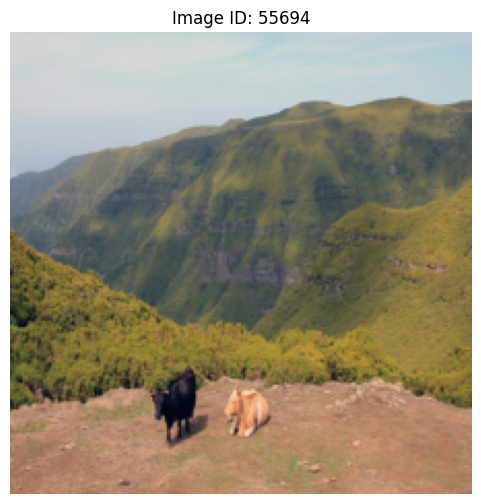


Total Q&A pairs: 12

Q1: What are these pack animals?
A1: oxen

Q2: Are the cows on a cliff?
A2: yes

Q3: What type of  animals are these?
A3: cows

Q4: Are the cows the same color?
A4: no

Q5: Can you milk this cow?
A5: no

Q6: What kind of animal is in the foreground?
A6: cow

Q7: Is there a horse?
A7: no

Q8: Are the cows eating grass?
A8: no

Q9: What type of animals are these?
A9: cows

Q10: Where are the cows?
A10: mountain top

Q11: Where are the livestock?
A11: on dirt

Q12: How many eyelashes does the cow have?
A12: 200



In [108]:
sanity_check_vqa_df(dataset,df)

### 2.3- Dataloading

In [71]:
from torch.utils.data import DataLoader

loader = DataLoader(dataset, batch_size=64, shuffle=True)
for batch_imgs, batch_ids in loader:
    print(batch_imgs.shape)  # should be [64, 3, 224, 224]
    print(batch_ids[:5])     # first 5 image_ids
    break

torch.Size([64, 3, 224, 224])
tensor([393031, 366867, 276969, 554711, 391972])
